<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Merged data shape: (763, 49)
Duplicate patient rows before filtering: 0

Target source: hpv_association_p16
Predictors: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
Target distribution:
HPV_Label
0    191
1    141
Name: count, dtype: int64

Rows: 332 | Train: 215 | Validation: 50 | Test: 67
Class counts (train): {0: 123, 1: 92}
Class counts (validation): {0: 29, 1: 21}
Class counts (test): {0: 39, 1: 28}

Original predictors: 6
One-hot encoded input features: 19
Training samples (no SMOTE): 215
Validation samples: 50
Test samples: 67

Automatic class weights: {0: 0.8739837398373984, 1: 1.1684782608695652}

Validation balanced accuracy: 0.6560
Selected validation threshold: 0.635

Validation metrics:
Accuracy             0.700000
Balanced_Accuracy    0.655993
Precision            0.800000
Recall               0.380952
F1                   0.516129
Threshold            0.635000
ROC_AUC           

,Model,N_Train,N_Validation,N_Test,Original_Predictor_Count,Encoded_Feature_Count,N_Estimators,Class_Weights,Validation_Accuracy,Validation_Balanced_Accuracy,...,Validation_ROC_AUC,Validation_PR_AUC,Test_Accuracy,Test_Balanced_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_Threshold,Test_ROC_AUC,Test_PR_AUC
0,Random Forest,215,50,67,6,19,100,"{0: 0.8739837398373984, 1: 1.1684782608695652}",0.7,0.655993,...,0.641215,0.647721,0.746269,0.711538,0.823529,0.5,0.622222,0.635,0.789377,0.810739


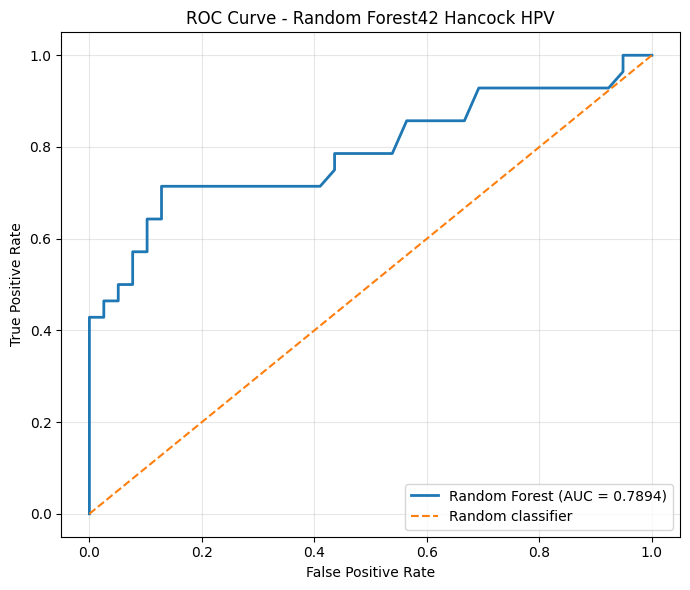

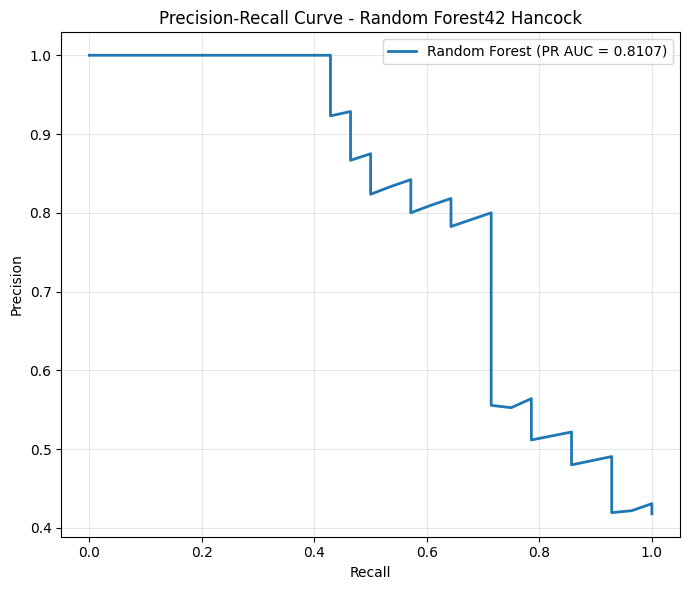


Feature importance (encoded predictors):
                      feature  importance
     age_at_initial_diagnosis    0.433009
                 pN_stage_pN2    0.134283
                 pN_stage_pN0    0.064663
        smoking_status_smoker    0.061979
                 pN_stage_pN1    0.046624
    smoking_status_non-smoker    0.037058
                pN_stage_pN2b    0.032066
                  pN_stage_NX    0.030379
        smoking_status_former    0.024195
                   sex_female    0.023404
                     sex_male    0.023077
                pN_stage_pN2a    0.021249
                pN_stage_pN3b    0.019120
                 pN_stage_pN3    0.017985
                pN_stage_pN2c    0.013742
     primarily_metastasis_yes    0.006281
      primarily_metastasis_no    0.006268
primary_tumor_site_Oropharynx    0.003200
       primary_tumor_site_CUP    0.001418


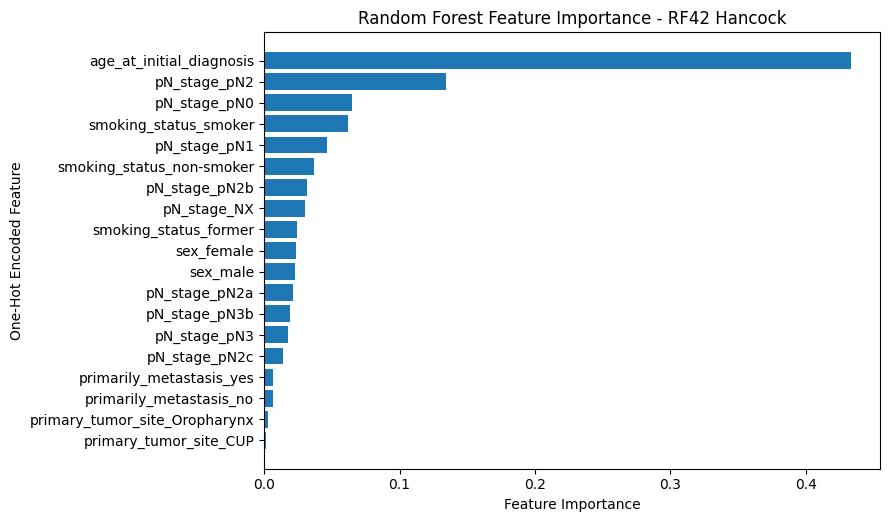


RANDOM FOREST42_HANCOCK SUMMARY
Model: Random Forest
Original predictors: 6
One-hot encoded features: 19
Estimators: 100
Random state: 42
Train / Validation / Test: 215 / 50 / 67
Split: Stratified 65 / 15 / 20
SMOTE: No
Class weights: Automatic, training data only
Encoding: OneHotEncoder(handle_unknown='ignore')
Scaling: StandardScaler on age only; fitted on training data
Threshold: Validation balanced accuracy over np.linspace(0.10, 0.90, 161)
Selected threshold: 0.635

Final test metrics:
Accuracy             0.746269
Balanced_Accuracy    0.711538
Precision            0.823529
Recall               0.500000
F1                   0.622222
Threshold            0.635000
ROC_AUC              0.789377
PR_AUC               0.810739
dtype: float64

Confusion matrix:
[[36  3]
 [14 14]]

Saved results folder: /content/drive/MyDrive/RF_results
Analysis complete.


In [1]:
# ============================================================
# RF42_HANCOCK — RANDOM FOREST HPV CLASSIFICATION
# Preprocessing, split, threshold selection, and reporting aligned
# with LR42_HANCOCK. Random Forest model configuration retained.
# Six original predictors | Seed 42 | No SMOTE | No data leakage
# ============================================================
import os,json,random,warnings,joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix,classification_report,roc_curve,precision_recall_curve
warnings.filterwarnings("ignore",category=FutureWarning)
SEED=42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"]=str(SEED)
drive.mount("/content/drive")
# ------------------------------------------------------------
# 1. LOAD AND PREPARE DATA
# ------------------------------------------------------------
BASE="/content/drive/MyDrive"
OUT_DIR=os.path.join(BASE,"RF_results")
os.makedirs(OUT_DIR,exist_ok=True)
def load_json_table(path):
    """Load JSON tables stored as lists or common record wrappers."""
    with open(path,"r",encoding="utf-8") as f:
        obj=json.load(f)
    if isinstance(obj,list):
        return pd.DataFrame(obj)
    if isinstance(obj,dict):
        for key in ["data","records","patients","items"]:
            if key in obj and isinstance(obj[key],list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)
    raise ValueError(f"Cannot read table from {path}")
clinical=load_json_table(os.path.join(BASE,"clinical_data.json"))
pathology=load_json_table(os.path.join(BASE,"pathological_data.json"))
if "patient_id" not in clinical.columns or "patient_id" not in pathology.columns:
    raise KeyError("Both clinical and pathological files must contain patient_id.")
df=clinical.merge(pathology,on="patient_id",how="left",suffixes=("","_path"))
print("Merged data shape:",df.shape)
print("Duplicate patient rows before filtering:",int(df["patient_id"].duplicated().sum()))
target_candidates=["hpv_association_p16","hpv_association_p16_path"]
target_col=next((c for c in target_candidates if c in df.columns),None)
if target_col is None:
    raise KeyError(f"Target not found. Available columns: {df.columns.tolist()}")
def normalize_label(value):
    """Normalize the label variants accepted by the LR notebook."""
    if pd.isna(value):
        return np.nan
    label=str(value).strip().lower()
    if label in {"positive","pos","1","true","yes"}:
        return 1
    if label in {"negative","neg","0","false","no"}:
        return 0
    return np.nan
feature_candidates={"age_at_initial_diagnosis":["age_at_initial_diagnosis"],"sex":["sex"],"smoking_status":["smoking_status"],"primary_tumor_site":["primary_tumor_site"],"primarily_metastasis":["primarily_metastasis"],"pN_stage":["pN_stage","pN_stage_path","pathological_N_stage","pathologic_N_stage","pathological_n_stage","pN"]}
resolved={}
for feature,candidates in feature_candidates.items():
    match=next((c for c in candidates if c in df.columns),None)
    if match is None:
        raise KeyError(f"Missing predictor '{feature}'; checked {candidates}")
    resolved[feature]=match
# Build a modelling frame with stable canonical predictor names.
model_df=pd.DataFrame(index=df.index)
model_df["patient_id"]=df["patient_id"]
for feature,source_col in resolved.items():
    model_df[feature]=df[source_col]
model_df["HPV_Label"]=df[target_col].map(normalize_label)
model_df=model_df.dropna(subset=["HPV_Label"]).copy()
model_df["HPV_Label"]=model_df["HPV_Label"].astype(int)
model_df=model_df.drop_duplicates(subset=["patient_id"],keep="first").copy()
features=list(feature_candidates.keys())
numeric_features=["age_at_initial_diagnosis"]
categorical_features=[c for c in features if c not in numeric_features]
# Normalize categorical strings and common missing-value spellings before splitting.
missing_strings={"","nan","none","null","na","n/a"}
for col in categorical_features:
    def clean_category(value):
        if pd.isna(value):
            return np.nan
        value=str(value).strip()
        return np.nan if value.lower() in missing_strings else value
    model_df[col]=model_df[col].apply(clean_category)
model_df["age_at_initial_diagnosis"]=pd.to_numeric(model_df["age_at_initial_diagnosis"],errors="coerce")
print("\nTarget source:",target_col)
print("Predictors:",features)
print("Target distribution:")
print(model_df["HPV_Label"].value_counts().sort_index())
# ------------------------------------------------------------
# 2. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
#    Same two-stage split as LR: 65% / 15% / 20%
# ------------------------------------------------------------
train_val,test=train_test_split(model_df,test_size=0.20,random_state=SEED,stratify=model_df["HPV_Label"])
train,val=train_test_split(train_val,test_size=0.1875,random_state=SEED,stratify=train_val["HPV_Label"])
train=train.copy()
val=val.copy()
test=test.copy()
print("\nRows:",len(model_df),"| Train:",len(train),"| Validation:",len(val),"| Test:",len(test))
print("Class counts (train):",train["HPV_Label"].value_counts().sort_index().to_dict())
print("Class counts (validation):",val["HPV_Label"].value_counts().sort_index().to_dict())
print("Class counts (test):",test["HPV_Label"].value_counts().sort_index().to_dict())
# ------------------------------------------------------------
# 3. PREPROCESSING — MATCH LR
#    Numeric age: median imputation + StandardScaler
#    Categorical predictors: most-frequent imputation + OneHotEncoder
#    Fit on training data only; unseen categories are ignored.
# ------------------------------------------------------------
try:
    onehot=OneHotEncoder(handle_unknown="ignore",sparse_output=False)
except TypeError:
    onehot=OneHotEncoder(handle_unknown="ignore",sparse=False)
preprocessor=ColumnTransformer(transformers=[("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),numeric_features),("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",onehot)]),categorical_features)],remainder="drop",verbose_feature_names_out=False)
X_train=preprocessor.fit_transform(train[features])
X_val=preprocessor.transform(val[features])
X_test=preprocessor.transform(test[features])
y_train=train["HPV_Label"].to_numpy()
y_val=val["HPV_Label"].to_numpy()
y_test=test["HPV_Label"].to_numpy()
ids_test=test["patient_id"].copy()
try:
    encoded_feature_names=preprocessor.get_feature_names_out().tolist()
except (AttributeError,TypeError):
    encoded_feature_names=[f"encoded_feature_{i}" for i in range(X_train.shape[1])]
n_features=X_train.shape[1]
print("\nOriginal predictors:",len(features))
print("One-hot encoded input features:",n_features)
print("Training samples (no SMOTE):",len(y_train))
print("Validation samples:",len(y_val))
print("Test samples:",len(y_test))
# ------------------------------------------------------------
# 4. AUTOMATIC CLASS WEIGHTS — TRAINING LABELS ONLY
# ------------------------------------------------------------
counts=np.bincount(y_train,minlength=2)
if np.any(counts==0):
    raise ValueError("Both HPV classes must be present in the training set.")
class_weight_dict={i:float(len(y_train)/(2*counts[i])) for i in range(2)}
print("\nAutomatic class weights:",class_weight_dict)
# ------------------------------------------------------------
# 5. TRAIN RANDOM FOREST
#    Retain original RF configuration: 100 trees, seed 42.
# ------------------------------------------------------------
model=RandomForestClassifier(n_estimators=100,class_weight=class_weight_dict,random_state=SEED)
model.fit(X_train,y_train)
# ------------------------------------------------------------
# 6. SELECT THRESHOLD USING VALIDATION ONLY — MATCH LR
#    161 thresholds from 0.10 to 0.90; maximise balanced accuracy;
#    ties resolved by threshold closest to 0.50.
# ------------------------------------------------------------
val_prob=model.predict_proba(X_val)[:,1]
thresholds=np.linspace(0.10,0.90,161)
threshold_scores=[balanced_accuracy_score(y_val,(val_prob>=threshold).astype(int)) for threshold in thresholds]
best_score=max(threshold_scores)
best_threshold=float(min((threshold for threshold,score in zip(thresholds,threshold_scores) if score==best_score),key=lambda threshold:abs(threshold-0.5)))
print(f"\nValidation balanced accuracy: {best_score:.4f}")
print(f"Selected validation threshold: {best_threshold:.3f}")
val_pred=(val_prob>=best_threshold).astype(int)
def calculate_metrics(y_true,probabilities,predictions,threshold):
    result={"Accuracy":accuracy_score(y_true,predictions),"Balanced_Accuracy":balanced_accuracy_score(y_true,predictions),"Precision":precision_score(y_true,predictions,zero_division=0),"Recall":recall_score(y_true,predictions,zero_division=0),"F1":f1_score(y_true,predictions,zero_division=0),"Threshold":float(threshold),"ROC_AUC":roc_auc_score(y_true,probabilities) if len(np.unique(y_true))==2 else np.nan,"PR_AUC":average_precision_score(y_true,probabilities) if len(np.unique(y_true))==2 else np.nan}
    return result
val_metrics=calculate_metrics(y_val,val_prob,val_pred,best_threshold)
# ------------------------------------------------------------
# 7. FINAL TEST EVALUATION — TEST SET USED ONCE
# ------------------------------------------------------------
test_prob=model.predict_proba(X_test)[:,1]
test_pred=(test_prob>=best_threshold).astype(int)
test_metrics=calculate_metrics(y_test,test_prob,test_pred,best_threshold)
print("\nValidation metrics:")
print(pd.Series(val_metrics))
print("\nTEST METRICS:")
print(pd.Series(test_metrics))
print("\nConfusion matrix:\n",confusion_matrix(y_test,test_pred,labels=[0,1]))
print("\nClassification report:\n",classification_report(y_test,test_pred,labels=[0,1],target_names=["HPV Negative","HPV Positive"],zero_division=0))
# ------------------------------------------------------------
# 8. SAVE RESULTS — SAME FILE STRUCTURE AS LR
#    Use RF_results so LR outputs are not overwritten.
# ------------------------------------------------------------
results_df=pd.DataFrame([{"Model":"Random Forest","N_Train":len(y_train),"N_Validation":len(y_val),"N_Test":len(y_test),"Original_Predictor_Count":len(features),"Encoded_Feature_Count":int(n_features),"N_Estimators":model.n_estimators,"Class_Weights":str(class_weight_dict),**{f"Validation_{key}":value for key,value in val_metrics.items()},**{f"Test_{key}":value for key,value in test_metrics.items()}}])
results_path=os.path.join(OUT_DIR,"metrics.csv")
results_df.to_csv(results_path,index=False)
predictions_df=pd.DataFrame({"patient_id":ids_test.to_numpy(),"y_true":y_test,"probability_positive":test_prob,"prediction":test_pred})
predictions_path=os.path.join(OUT_DIR,"test_predictions.csv")
predictions_df.to_csv(predictions_path,index=False)
settings={"model":"RandomForestClassifier","seed":SEED,"features":features,"selected_source_columns":resolved,"target_column":target_col,"target_mapping":{"positive":1,"pos":1,"1":1,"true":1,"yes":1,"negative":0,"neg":0,"0":0,"false":0,"no":0},"threshold":best_threshold,"validation_balanced_accuracy":float(best_score),"class_weight":class_weight_dict,"smote":False,"split":{"train":len(train),"validation":len(val),"test":len(test),"train_fraction_approx":0.65,"validation_fraction_approx":0.15,"test_fraction":0.20,"stratified":True,"random_state":SEED},"preprocessing":{"numeric":"Median imputation then StandardScaler; fit on training data only","categorical":"Most-frequent imputation then OneHotEncoder(handle_unknown='ignore'); fit on training data only"},"encoded_feature_names":encoded_feature_names}
with open(os.path.join(OUT_DIR,"settings.json"),"w",encoding="utf-8") as f:
    json.dump(settings,f,indent=2)
# Save model together with preprocessing needed for future predictions.
joblib.dump({"model":model,"preprocessor":preprocessor,"features":features,"numeric_features":numeric_features,"categorical_features":categorical_features,"selected_source_columns":resolved,"target_column":target_col,"threshold":best_threshold,"encoded_feature_names":encoded_feature_names},os.path.join(OUT_DIR,"RF42_Hancock_model.joblib"))
print("\nSaved metrics to:",results_path)
print("Saved test predictions to:",predictions_path)
print("\nTest results:")
display(results_df)
# ------------------------------------------------------------
# 9. ROC / AUC CURVE
# ------------------------------------------------------------
fpr,tpr,_=roc_curve(y_test,test_prob)
auc_curve=roc_auc_score(y_test,test_prob)
plt.figure(figsize=(7,6))
plt.plot(fpr,tpr,linewidth=2,label=f"Random Forest (AUC = {auc_curve:.4f})")
plt.plot([0,1],[0,1],linestyle="--",linewidth=1.5,label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest42 Hancock HPV")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"roc_curve.png"),dpi=300,bbox_inches="tight")
plt.show()
# ------------------------------------------------------------
# 10. PRECISION-RECALL CURVE
# ------------------------------------------------------------
precision_values,recall_values,_=precision_recall_curve(y_test,test_prob)
pr_auc_curve=average_precision_score(y_test,test_prob)
plt.figure(figsize=(7,6))
plt.plot(recall_values,precision_values,linewidth=2,label=f"Random Forest (PR AUC = {pr_auc_curve:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest42 Hancock")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"precision_recall_curve.png"),dpi=300,bbox_inches="tight")
plt.show()
# ------------------------------------------------------------
# 11. RANDOM FOREST FEATURE IMPORTANCE
#    Importance is reported for the encoded features, as required
#    after one-hot encoding.
# ------------------------------------------------------------
feature_importance=pd.DataFrame({"feature":encoded_feature_names,"importance":model.feature_importances_}).sort_values("importance",ascending=False)
feature_importance.to_csv(os.path.join(OUT_DIR,"feature_importance.csv"),index=False)
print("\nFeature importance (encoded predictors):")
print(feature_importance.to_string(index=False))
top_n=min(25,len(feature_importance))
plot_importance=feature_importance.head(top_n).sort_values("importance")
plt.figure(figsize=(9,max(5,0.28*top_n)))
plt.barh(plot_importance["feature"],plot_importance["importance"])
plt.xlabel("Feature Importance")
plt.ylabel("One-Hot Encoded Feature")
plt.title("Random Forest Feature Importance - RF42 Hancock")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"feature_importance.png"),dpi=300,bbox_inches="tight")
plt.show()
# ------------------------------------------------------------
# 12. MODEL SUMMARY
# ------------------------------------------------------------
print("\n====================================")
print("RANDOM FOREST42_HANCOCK SUMMARY")
print("====================================")
print("Model: Random Forest")
print("Original predictors:",len(features))
print("One-hot encoded features:",n_features)
print("Estimators:",model.n_estimators)
print("Random state:",SEED)
print("Train / Validation / Test:",f"{len(train)} / {len(val)} / {len(test)}")
print("Split: Stratified 65 / 15 / 20")
print("SMOTE: No")
print("Class weights: Automatic, training data only")
print("Encoding: OneHotEncoder(handle_unknown='ignore')")
print("Scaling: StandardScaler on age only; fitted on training data")
print("Threshold: Validation balanced accuracy over np.linspace(0.10, 0.90, 161)")
print("Selected threshold:",f"{best_threshold:.3f}")
print("\nFinal test metrics:")
print(pd.Series(test_metrics))
print("\nConfusion matrix:")
print(confusion_matrix(y_test,test_pred,labels=[0,1]))
print("\nSaved results folder:",OUT_DIR)
print("Analysis complete.")